# Scholarships, Debt and Student Outcomes

## Setup

In [1]:
!pip install ucimlrepo

In [2]:
# Libraries used in this notebook
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from collections import Counter
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [3]:
# Load the dataset once and clean column names (remove leading and trailing whitespace)
df = fetch_ucirepo(id=697).data.original
df.columns = df.columns.str.strip()

sns.set(style="whitegrid")

# Fit a logistic regression of one column on another and print the summary
# add_constant adds an intercept column so the model can learn one
def logit_summary(outcome, predictor, title=None):
    result = sm.Logit(df[outcome], sm.add_constant(df[predictor])).fit()
    if title:
        print(title + "\n")
    print(result.summary())

# Percentage of students in a group with tuition fees not up to date
def unpaid_tuition_pct(group):
    group_df = df[df['Target'] == group]
    return (group_df['Tuition fees up to date'] == 0).sum() / len(group_df) * 100

## Scholarships and Debt

In [4]:
# How Admission Grade affects the likelihood of being a Scholarship Holder
logit_summary('Scholarship holder', 'Admission grade',
              "To investigate how Admission Grade affects the likelihood of being a Scholarship Holder")

# p-value of 0.209 indicates that the relationship between Admission Grade and Scholarship Holder is not statistically significant at the 0.05 level.
# This suggests that Admission Grade does not have a strong influence on whether a student is a Scholarship Holder in this dataset.

Optimization terminated successfully.
         Current function value: 0.560413
         Iterations 5
To investigate how Admission Grade affects the likelihood of being a Scholarship Holder

                           Logit Regression Results                           
Dep. Variable:     Scholarship holder   No. Observations:                 4424
Model:                          Logit   Df Residuals:                     4422
Method:                           MLE   Df Model:                            1
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:               0.0003168
Time:                        19:37:56   Log-Likelihood:                -2479.3
converged:                       True   LL-Null:                       -2480.1
Covariance Type:            nonrobust   LLR p-value:                    0.2100
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const    

In [5]:
# How being a Scholarship Holder affects the likelihood of being a Debtor
logit_summary('Debtor', 'Scholarship holder')

# p-value of 0.000 indicates that the relationship between Scholarship Holder and Debtor is statistically significant at the 0.05 level.
# The negative coefficient means Scholarship Holders are less likely to be Debtors,
# i.e. less likely to have unpaid tuition fees than students without a scholarship.

Optimization terminated successfully.
         Current function value: 0.351720
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                 Debtor   No. Observations:                 4424
Model:                          Logit   Df Residuals:                     4422
Method:                           MLE   Df Model:                            1
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                0.006939
Time:                        19:37:56   Log-Likelihood:                -1556.0
converged:                       True   LL-Null:                       -1566.9
Covariance Type:            nonrobust   LLR p-value:                 3.114e-06
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -1.9367      0.052    -37.061      0.000      -2.039      -1.834
Schol

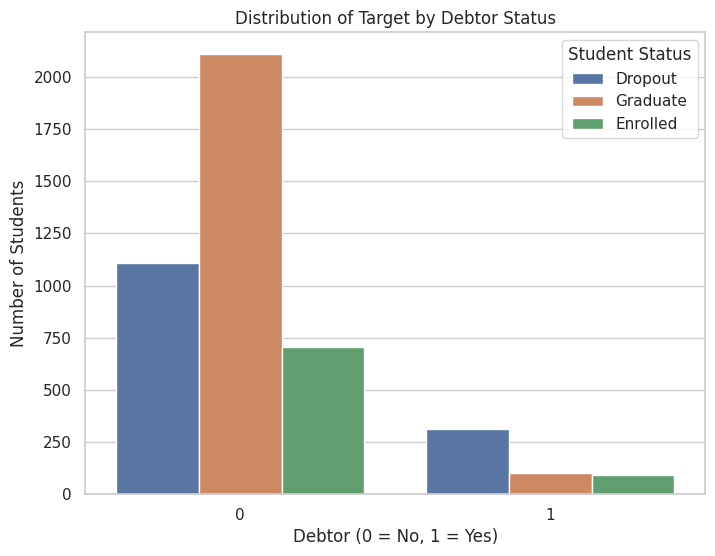

Percentage of each outcome by Debtor status:
Target  Dropout  Enrolled  Graduate
Debtor                             
0         28.28     17.95     53.76
1         62.03     17.89     20.08


In [6]:
# Distribution of student outcome by debtor status
df_filtered = df.dropna(subset=['Debtor', 'Target'])

plt.figure(figsize=(8, 6))
sns.countplot(data=df_filtered, x='Debtor', hue='Target')   # Count of each outcome within Debtor = 0 and Debtor = 1
plt.title("Distribution of Target by Debtor Status")
plt.xlabel("Debtor (0 = No, 1 = Yes)")
plt.ylabel("Number of Students")
plt.legend(title="Student Status")
plt.show()

# Percentage of each outcome within each debtor group
cross_tab = pd.crosstab(df_filtered['Debtor'], df_filtered['Target'], normalize='index') * 100
print("Percentage of each outcome by Debtor status:")
print(cross_tab.round(2))

## Dropout Rate and Unpaid Tuition

In [7]:
# Dropout rate in the dataset
total_students = df['Target'].notna().sum()
dropout_df = df[df['Target'] == 'Dropout']
num_dropouts = len(dropout_df)

print(f"Total students: {total_students}")
print(f"Number of dropouts: {num_dropouts}")
print(f"Dropout rate: {num_dropouts / total_students * 100:.2f}%")

Total students: 4424
Number of dropouts: 1421
Dropout rate: 32.12%


In [8]:
# Percentage of dropout students with unpaid tuition fees ('Tuition fees up to date' = 0)
print(f"Percentage of dropout students with unpaid tuition: {unpaid_tuition_pct('Dropout'):.2f}%")

Percentage of dropout students with unpaid tuition: 32.16%


In [9]:
# Percentage of graduates with unpaid tuition fees
print(f"Percentage of graduates with unpaid tuition: {unpaid_tuition_pct('Graduate'):.2f}%")

Percentage of graduates with unpaid tuition: 1.31%


In [10]:
# Dropout students with unpaid tuition fees who also hold a scholarship
count = ((dropout_df['Tuition fees up to date'] == 0) & (dropout_df['Scholarship holder'] == 1)).sum()

print(f"Number of dropout students with unpaid tuition and scholarships: {count}")
print(f"Percentage of dropout students in this group: {count / num_dropouts * 100:.2f}%")

Number of dropout students with unpaid tuition and scholarships: 28
Percentage of dropout students in this group: 1.97%


## Predicting Student Outcome with Class Balancing

In [11]:
# Encode text columns as numbers and split the data
df_encoded = df.dropna(subset=['Target', 'Tuition fees up to date', 'Scholarship holder']).copy()
for col in df_encoded.select_dtypes(include='object'):
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col].astype(str))

X = df_encoded.drop(columns=['Target'])
y = df_encoded['Target']   # 0 = Dropout, 1 = Enrolled, 2 = Graduate
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Resample the training data, train a Random Forest and print its classification report
def resample_and_evaluate(sampler, dist_label, report_label):
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    print(dist_label, Counter(y_res))
    model = RandomForestClassifier(random_state=42).fit(X_res, y_res)
    print(report_label)
    print(classification_report(y_test, model.predict(X_test)))

# SMOTE creates synthetic samples of the minority classes
print("Original class distribution:", Counter(y))
resample_and_evaluate(SMOTE(random_state=42), "Balanced class distribution:",
                      "\nClassification Report after SMOTE training:")

# Precision is the share of predicted positives that were actually positive.
# Recall is the share of actual positives that were correctly predicted.
# F1-score is the harmonic mean of precision and recall.

Original class distribution: Counter({2: 2209, 0: 1421, 1: 794})
Balanced class distribution: Counter({0: 1567, 2: 1567, 1: 1567})

Classification Report after SMOTE training:
              precision    recall  f1-score   support

           0       0.84      0.73      0.78       441
           1       0.49      0.49      0.49       245
           2       0.81      0.88      0.84       642

    accuracy                           0.76      1328
   macro avg       0.71      0.70      0.70      1328
weighted avg       0.76      0.76      0.76      1328



In [12]:
# Random oversampling duplicates minority class samples until all classes are balanced
print("Before oversampling:", Counter(y_train))
resample_and_evaluate(RandomOverSampler(random_state=42), "After oversampling:", "Performance after oversampling:")

Before oversampling: Counter({2: 1567, 0: 980, 1: 549})
After oversampling: Counter({0: 1567, 2: 1567, 1: 1567})
Performance after oversampling:
              precision    recall  f1-score   support

           0       0.82      0.77      0.79       441
           1       0.57      0.46      0.51       245
           2       0.81      0.90      0.85       642

    accuracy                           0.78      1328
   macro avg       0.73      0.71      0.72      1328
weighted avg       0.77      0.78      0.77      1328



In [13]:
# Random undersampling removes majority class samples (Enrolled and Graduate) to balance the classes
resample_and_evaluate(RandomUnderSampler(random_state=42), "Undersampled class distribution:", "Performance after undersampling:")

# Undersampling loses some information from the majority class, but can reduce overfitting to it.

Undersampled class distribution: Counter({0: 549, 1: 549, 2: 549})
Performance after undersampling:
              precision    recall  f1-score   support

           0       0.85      0.69      0.76       441
           1       0.42      0.62      0.50       245
           2       0.84      0.79      0.82       642

    accuracy                           0.73      1328
   macro avg       0.70      0.70      0.69      1328
weighted avg       0.76      0.73      0.74      1328

